### Freight Demand Forecasting

### Data

Monthly Transportation Statistics from the US Bureau of Transportation Statistics (public data). The file contains 136 monthly series on one timeline starting in 1947. The series used here is **Freight Rail Intermodal Units**, the number of shipping containers and trailers moved by rail each month.

The aim is to forecast this series 24 months ahead and to check whether a forecasting model performs better than simple baseline rules.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

### 1. Loading the Data

In [2]:
df = pd.read_csv('monthly_transportation_statistics.csv')
df.head()

,Index,Date,Air Safety - General Aviation Fatalities,Highway Fatalities Per 100 Million Vehicle Miles Traveled,Highway Fatalities,U.S. Airline Traffic - Total - Seasonally Adjusted,U.S. Airline Traffic - International - Seasonally Adjusted,U.S. Airline Traffic - Domestic - Seasonally Adjusted,Transit Ridership - Other Transit Modes - Adjusted,Transit Ridership - Fixed Route Bus - Adjusted,...,Heavy truck sales SAAR (millions),U.S. Airline Traffic - Total - Non Seasonally Adjusted,Light truck sales SAAR (millions),U.S. Airline Traffic - International - Non Seasonally Adjusted,Auto sales SAAR (millions),U.S. Airline Traffic - Domestic - Non Seasonally Adjusted,Transborder - Total North American Freight,Transborder - U.S. - Mexico Freight,U.S. marketing air carriers on-time performance (percent),Transborder - U.S. - Canada Freight
0,0,01/01/1947 12:00:00 AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,1,02/01/1947 12:00:00 AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,2,03/01/1947 12:00:00 AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,3,04/01/1947 12:00:00 AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,4,05/01/1947 12:00:00 AM,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [3]:
df.isnull().sum()

Index                                                          0
Date                                                           0
Air Safety - General Aviation Fatalities                     415
Highway Fatalities Per 100 Million Vehicle Miles Traveled    905
Highway Fatalities                                           886
                                                            ... 
U.S. Airline Traffic - Domestic - Non Seasonally Adjusted    640
Transborder - Total North American Freight                   712
Transborder - U.S. - Mexico Freight                          712
U.S. marketing air carriers on-time performance (percent)    855
Transborder - U.S. - Canada Freight                          712
Length: 136, dtype: int64

In [4]:
df.shape

(959, 136)

In [5]:
print(df.columns)

Index(['Index', 'Date', 'Air Safety - General Aviation Fatalities',
       'Highway Fatalities Per 100 Million Vehicle Miles Traveled',
       'Highway Fatalities',
       'U.S. Airline Traffic - Total - Seasonally Adjusted',
       'U.S. Airline Traffic - International - Seasonally Adjusted',
       'U.S. Airline Traffic - Domestic - Seasonally Adjusted',
       'Transit Ridership - Other Transit Modes - Adjusted',
       'Transit Ridership - Fixed Route Bus - Adjusted',
       ...
       'Heavy truck sales SAAR (millions)',
       'U.S. Airline Traffic - Total - Non Seasonally Adjusted',
       'Light truck sales SAAR (millions)',
       'U.S. Airline Traffic - International - Non Seasonally Adjusted',
       'Auto sales SAAR (millions)',
       'U.S. Airline Traffic - Domestic - Non Seasonally Adjusted',
       'Transborder - Total North American Freight',
       'Transborder - U.S. - Mexico Freight',
       'U.S. marketing air carriers on-time performance (percent)',
       'Transb

In [6]:
df['Date'].dtype

dtype('O')

### 2. Data Cleaning and Timeline Checks

In [7]:
freight_df = df[["Date", "Freight Rail Intermodal Units"]]

In [8]:
freight_df.loc[:, 'Date'] = pd.to_datetime(freight_df['Date'], format='mixed', errors='coerce')
freight_df.head()

,Date,Freight Rail Intermodal Units
0,1947-01-01 00:00:00,NaN
1,1947-02-01 00:00:00,NaN
2,1947-03-01 00:00:00,NaN
3,1947-04-01 00:00:00,NaN
4,1947-05-01 00:00:00,NaN


In [9]:
freight_df = freight_df.dropna(subset=['Freight Rail Intermodal Units'])
freight_df.isnull().sum()
freight_df.head()

,Date,Freight Rail Intermodal Units
504,1989-01-01 00:00:00,408900.0
505,1989-02-01 00:00:00,442989.0
506,1989-03-01 00:00:00,442634.0
507,1989-04-01 00:00:00,555066.0
508,1989-05-01 00:00:00,437692.0


In [10]:
freight_df = freight_df.set_index('Date')
freight_df = freight_df.sort_index()

c:\Users\rupal\AppData\Local\Programs\Python\Python313\Lib\site-packages\pandas\core\indexes\base.py:7654: FutureWarning: Dtype inference on a pandas object (Series, Index, ExtensionArray) is deprecated. The Index constructor will keep the original dtype in the future. Call `infer_objects` on the result to get the old behavior.
  return Index(sequences[0], name=names)


In [11]:
freight_df.head(20)

,Freight Rail Intermodal Units
Date,
1989-01-01,408900.0
1989-02-01,442989.0
1989-03-01,442634.0
1989-04-01,555066.0
1989-05-01,437692.0
1989-06-01,427200.0
1989-07-01,531988.0
1989-08-01,446898.0
1989-09-01,574760.0


In [12]:
first_date = freight_df.index.min()
last_date = freight_df.index.max()

print("first date: ", first_date)
print("last date: ", last_date)

first date:  1989-01-01 00:00:00
last date:  2026-07-01 00:00:00


In [13]:
print("Number of rows: ", freight_df.shape[0])

Number of rows:  452


In [14]:
print("Number of duplicate dates: ", freight_df.index.duplicated().sum())

Number of duplicate dates:  1


In [16]:
freight_df = freight_df[~freight_df.index.duplicated(keep='first')]
freight_df.index.duplicated().sum()

np.int64(0)

In [17]:
print("Number of rows: ", freight_df.shape[0])

Number of rows:  451


In [22]:
full_date_range = pd.date_range(start=first_date, end=last_date, freq='MS')

In [34]:
missing_dates = []

for date in full_date_range:
    if date not in freight_df.index:
        missing_dates.append(date)

if len(missing_dates)==0:
    print("All dates match")
else:
    print("Missing dates:", missing_dates)

All dates match


In [30]:
len(full_date_range.difference(freight_df.index))


0

### Observations
- Most columns had a large number of missing values because each of the 136 series started being recorded in a different year. Only the date and the Freight Rail Intermodal Units columns were kept.
- Rows before January 1989 were dropped, as this series was not recorded before then.
- One duplicated month (April 2023) with identical values was found in the source file and removed.
- After cleaning, the series contained 451 months from January 1989 to July 2026, with no duplicates and no missing months.

### 3. Exploratory Analysis - Trend and Seasonality

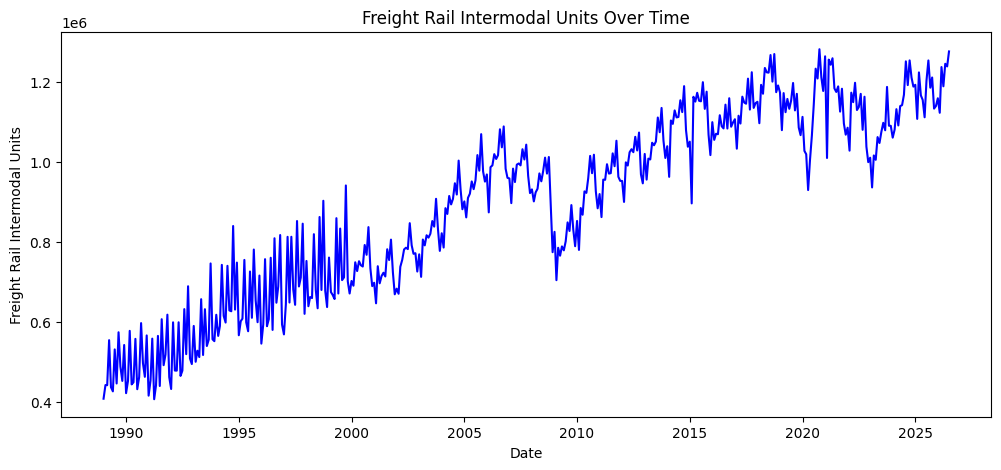

In [47]:
plt.figure(figsize=(12,5))
plt.plot(freight_df.index, freight_df['Freight Rail Intermodal Units'], color='blue')
plt.xlabel('Date')
plt.ylabel('Freight Rail Intermodal Units')
plt.title('Freight Rail Intermodal Units Over Time')
plt.show()

In [52]:
monthly_avg = freight_df['Freight Rail Intermodal Units'].groupby(freight_df.index.month).mean()

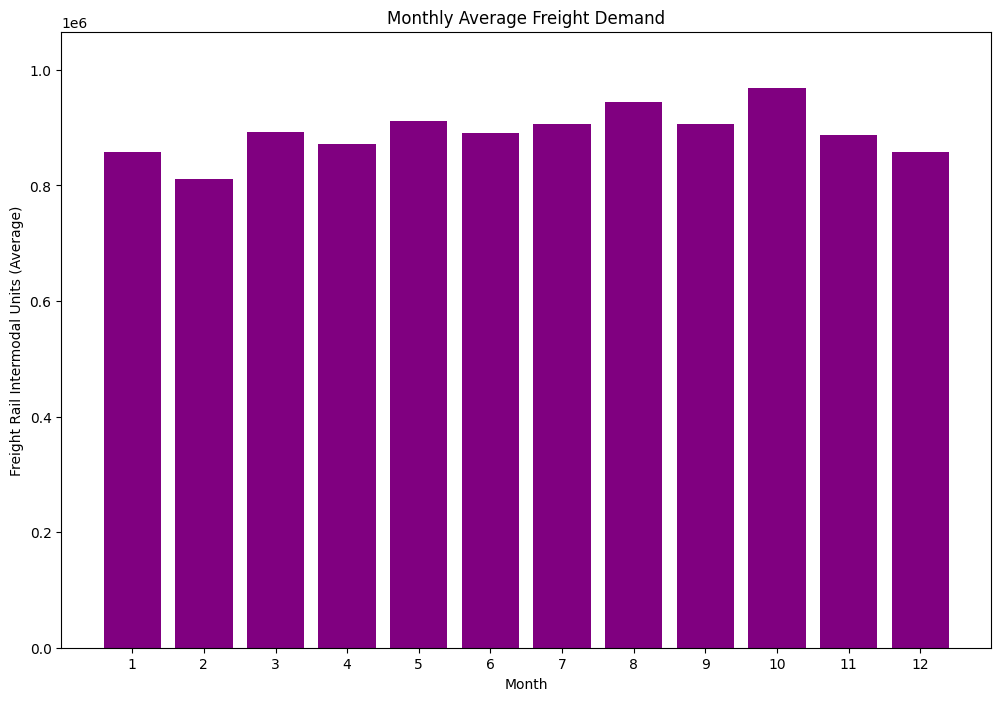

In [58]:
plt.figure(figsize=(12,8))
plt.bar(range(1,13), monthly_avg, color='purple')
plt.xlabel('Month')
plt.xticks(range(1, 13))
plt.ylabel('Freight Rail Intermodal Units (Average)')
plt.ylim(0, monthly_avg.max() * 1.1)
plt.title('Monthly Average Freight Demand')
plt.show()

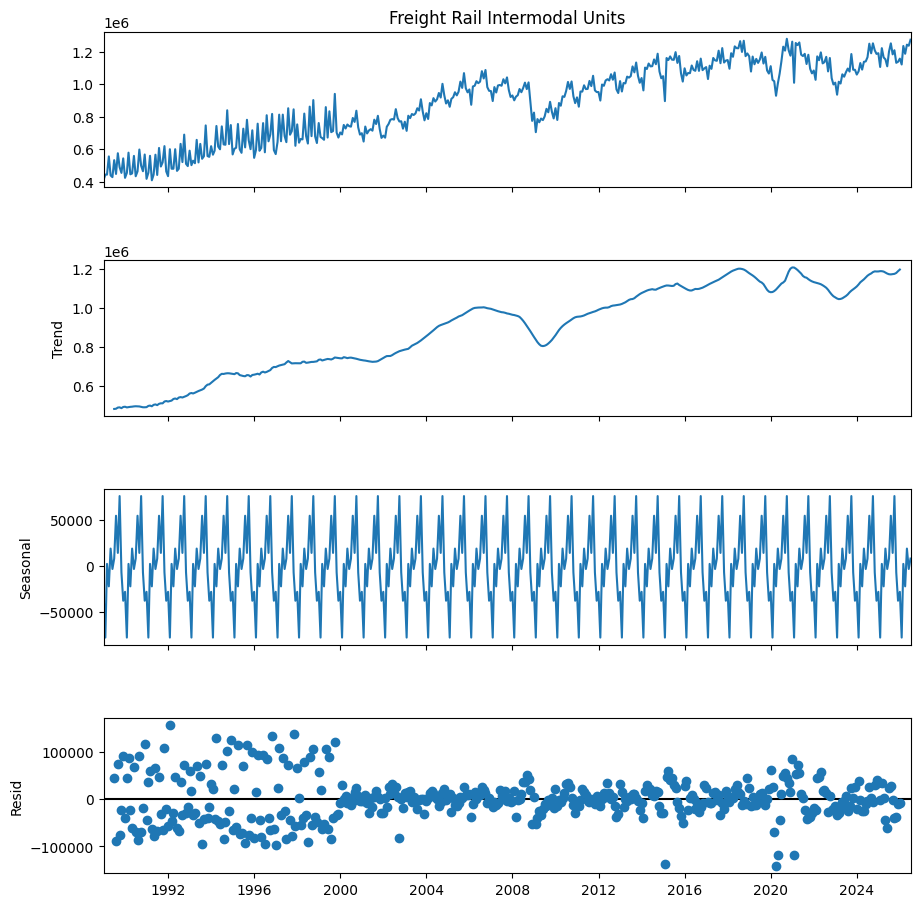

In [74]:
from statsmodels.tsa.seasonal import seasonal_decompose

result = seasonal_decompose(freight_df['Freight Rail Intermodal Units'], period=12)
fig = result.plot()
fig.set_size_inches(10,10)
plt.show()



### Observations
- Over the 37 years, demand was mostly rising. Steady growth was seen from 1989 to 2006, followed by a dip between 2008 and 2012, after which demand grew again. From 2016 onwards it remained more stable, with small fluctuations.
- A stable yearly seasonal pattern was observed. Demand was lowest around February and highest in August and October.
- The residuals (what is left after removing trend and seasonality) were larger before 2000 and again from 2020 onwards. This indicated that the seasonal pattern was different in the early years, and that 2020 was an unusual event.

### 4. Train-Test Split

In [76]:
y = freight_df['Freight Rail Intermodal Units']

train = y.loc[:"2024-07-31"]
test = y.loc["2024-08-01":"2026-07-31"]

In [86]:
print(train.index[0])
print(train.index[-1])
print(len(train))

print(test.index[0])
print(test.index[-1])
print(len(test))


1989-01-01 00:00:00
2024-07-01 00:00:00
427
2024-08-01 00:00:00
2026-07-01 00:00:00
24


***The last 24 months (August 2024 to July 2026) were kept as the test set and everything before was used for training. The data was split by time and not randomly, because the model must only learn from the past.***

### 5. Baseline Forecasts

In [88]:
naive_value = train.iloc[-1]

naive_forecast = pd.Series(naive_value, index=test.index)
print(naive_forecast)

Date
2024-08-01    1167756.0
2024-09-01    1167756.0
2024-10-01    1167756.0
2024-11-01    1167756.0
2024-12-01    1167756.0
2025-01-01    1167756.0
2025-02-01    1167756.0
2025-03-01    1167756.0
2025-04-01    1167756.0
2025-05-01    1167756.0
2025-06-01    1167756.0
2025-07-01    1167756.0
2025-08-01    1167756.0
2025-09-01    1167756.0
2025-10-01    1167756.0
2025-11-01    1167756.0
2025-12-01    1167756.0
2026-01-01    1167756.0
2026-02-01    1167756.0
2026-03-01    1167756.0
2026-04-01    1167756.0
2026-05-01    1167756.0
2026-06-01    1167756.0
2026-07-01    1167756.0
dtype: float64


In [89]:
seasonal_naive_values = train.iloc[-12:].values
seasonal_naive_values = np.tile(seasonal_naive_values, 2)

seasonal_naive_forecast = pd.Series(seasonal_naive_values, index=test.index)
print(seasonal_naive_forecast)

Date
2024-08-01    1097725.0
2024-09-01    1079107.0
2024-10-01    1187306.0
2024-11-01    1090452.0
2024-12-01    1090131.0
2025-01-01    1060637.0
2025-02-01    1080697.0
2025-03-01    1131742.0
2025-04-01    1091151.0
2025-05-01    1139363.0
2025-06-01    1141889.0
2025-07-01    1167756.0
2025-08-01    1097725.0
2025-09-01    1079107.0
2025-10-01    1187306.0
2025-11-01    1090452.0
2025-12-01    1090131.0
2026-01-01    1060637.0
2026-02-01    1080697.0
2026-03-01    1131742.0
2026-04-01    1091151.0
2026-05-01    1139363.0
2026-06-01    1141889.0
2026-07-01    1167756.0
dtype: float64


In [90]:
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error

In [96]:
# Naive error

naive_mae = mean_absolute_error(test, naive_forecast)
naive_mape = mean_absolute_percentage_error(test, naive_forecast)

print(f"Naive MAE: {naive_mae:.3f}")
print(f"Naive MAPE: {naive_mape:.1%}")

Naive MAE: 46350.958
Naive MAPE: 3.8%


In [97]:
# Seasonal Naive error

seasonal_naive_mae = mean_absolute_error(test, seasonal_naive_forecast)
seasonal_naive_mape = mean_absolute_percentage_error(test, seasonal_naive_forecast)

print(f"Seasonal Naive MAE: {seasonal_naive_mae:.3f}")
print(f"Seasonal Naive MAPE: {seasonal_naive_mape:.1%}")

Seasonal Naive MAE: 82843.125
Seasonal Naive MAPE: 6.9%


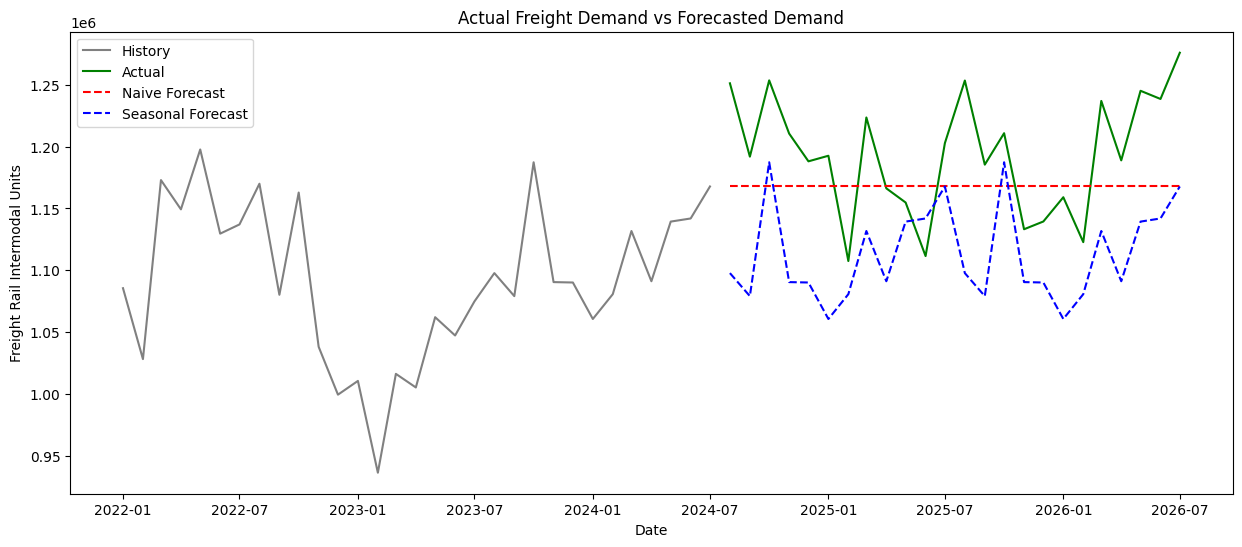

In [104]:
plt.figure(figsize=(15,6))
plt.plot(train['2022':], label='History', color='grey')
plt.plot(test, label='Actual', color='green')
plt.plot(naive_forecast, label='Naive Forecast', color='red', linestyle='--')
plt.plot(seasonal_naive_forecast, label='Seasonal Forecast', color='blue', linestyle='--')
plt.title('Actual Freight Demand vs Forecasted Demand')
plt.xlabel('Date')
plt.ylabel('Freight Rail Intermodal Units')
plt.legend()
plt.show()

### Observations
- Two baselines were built: a naive forecast (every future month equals the last known month) and a seasonal naive forecast (every future month equals the same month one year earlier).
- The naive forecast had the lower error (MAPE 3.8%), but it is a flat line and gives no information about which months will be busy.
- The seasonal naive forecast followed the yearly pattern but stayed well below the actual values (MAPE 6.9%), because the year it copied (2023-24) was a low year.
- Therefore, a good model needs to capture both the level of demand and the seasonal pattern.

### 6. Stationarity and Differencing

In [105]:
# selecting train data between Jan 2010 to July 2024, as there is a sub-trend in freight demand, where demand dipped around 2009-10 and starter raising again
train_recent = train.loc['2010-01-01':'2024-07-01']
print(len(train_recent))

175


In [112]:
# test for stationarity

from statsmodels.tsa.stattools import adfuller

stationarity = adfuller(train_recent)
print(f"p-value: {stationarity[1]:.4f}")

p_value = stationarity[1]

if p_value < 0.05:
    print("Stationary")
else:
    print("Non-stationary")

p-value: 0.1389
Non-stationary


In [161]:
# differencing the data to make it stationary, so model can learn from it

first_diff = train_recent.diff().dropna()
seasonal_diff = first_diff.diff(12).dropna()

first_diff_adfuller = adfuller(first_diff)
print(f"p-value after 1st differencing: {first_diff_adfuller[1]:.4f}")

seasonal_diff_adfuller = adfuller(seasonal_diff)
print(f"p-value after first + seasonal differencing: {seasonal_diff_adfuller[1]:.4f}")

# check for stationarity
first_diff_pval = first_diff_adfuller[1]
seasonal_diff_pval = seasonal_diff_adfuller[1]

if first_diff_pval < 0.05 and seasonal_diff_pval < 0.05:
    print("Data is stationary")
else:
    print("Data is not stationary")

p-value after 1st differencing: 0.0008
p-value after first + seasonal differencing: 0.0000
Data is stationary


### Observations
- Training data from January 2010 onwards was used, since demand dipped around 2008-09 before rising again and the earlier seasonal pattern was less stable.
- The original series was not stationary (p-value 0.14).
- After first differencing the series became stationary (p-value below 0.05), so d = 1 was used.
- A seasonal difference of 12 months was also applied to remove the yearly pattern, so D = 1 was used.

### 7. ACF and PACF Plots

Figure(640x480)
Figure(640x480)


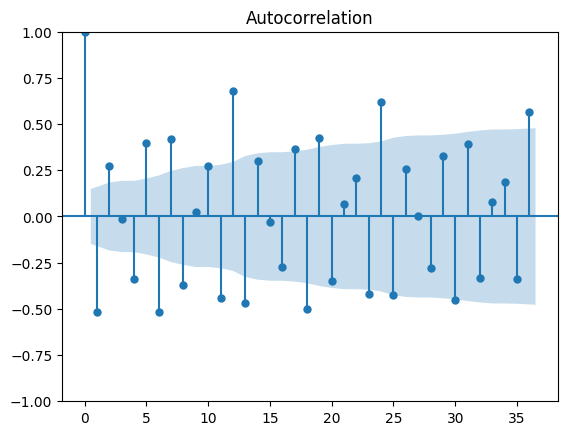

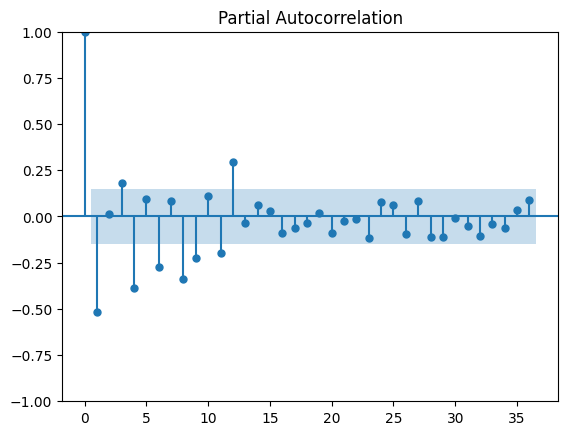

In [122]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

first_diff_acf = plot_acf(first_diff, lags=36)
first_diff_pacf = plot_pacf(first_diff, lags=36)

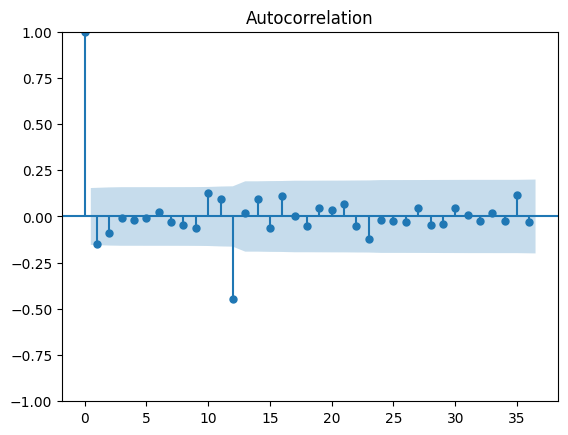

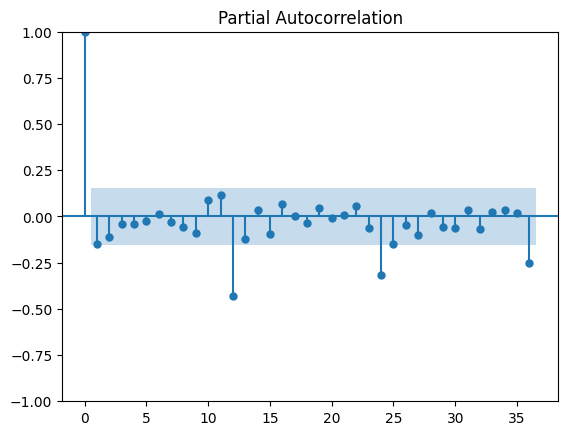

In [123]:
seasonal_diff_acf = plot_acf(seasonal_diff, lags=36)
seasonal_diff_pacf = plot_pacf(seasonal_diff, lags=36)

### Observations
- After first differencing, the ACF plot still showed three large spikes at lags 12, 24 and 36, indicating that the yearly pattern was still present.
- After seasonal differencing, those spikes were no longer present and most values were inside the band, with one spike remaining at lag 12. This suggested one seasonal moving-average(MA) term (Q = 1).
- The first few lags were small in both plots, so the non-seasonal p and q were expected to be 0 or 1.

### 8. Model Selection - SARIMA

In [ ]:
# Model training and Akaike Information Criterion(AIC) calculation - a measure of how badly a model fits -> lower aic, the better
from statsmodels.tsa.statespace.sarimax import SARIMAX

train_recent = train_recent.asfreq('MS')
sarimax_model = SARIMAX(train_recent, order=(0,1,1), seasonal_order=(0,1,1,12))

sarimax_result = sarimax_model.fit(disp=False)
print(f"AIC: {sarimax_result.aic:.4f}")

AIC: 3955.7562


In [139]:
orders_list = [(0,1,1), (1,1,1), (1,1,0), (0,1,0)]
results = []

for i,order in enumerate(orders_list):
    model = SARIMAX(train_recent, order=order, seasonal_order=(0,1,1,12))
    model_result = model.fit(disp=False)
    results.append(model_result)
    print(f"Model {i+1} AIC: {model_result.aic:.4f}")
print(f"Model with lowest AIC: {np.argmin([r.aic for r in results])+1}")



Model 1 AIC: 3955.7562
Model 2 AIC: 3957.2354
Model 3 AIC: 3955.6077
Model 4 AIC: 3954.9227
Model with lowest AIC: 4


### Observations
- Four SARIMA models suggested by the plots were fitted and compared using AIC (a measure of how badly a model fits, with a penalty for extra terms; lower is better).
- The four AIC values were almost the same(within 2 points difference), meaning the additional non-seasonal terms did not improve the fit.
- The simplest model, which also had the lowest AIC, was selected: SARIMA (0,1,0) (0,1,1,12).

### 9. Forecast and Evaluation

In [160]:
#forecast demand and evaluate model performance

best_model = SARIMAX(train_recent, order=(0,1,0), seasonal_order=(0,1,1,12))
best_result = best_model.fit(disp=False)

#forecast demand 24 months ahead
forecast = best_result.get_forecast(steps=24).predicted_mean

# evaluate MAE and MAPE
best_model_mae = mean_absolute_error(test, forecast)
best_model_mape = mean_absolute_percentage_error(test, forecast)

print(f"Best model MAE: {best_model_mae:.4f}")
print(f"Best model MAPE: {best_model_mape:.4f}")

Best model MAE: 32923.9693
Best model MAPE: 0.0276


In [151]:
# comparing with naive, seasonal naive and best SARIMAX model
model_data = {'Model': ['Naive', 'Seasonal Naive', 'SARIMAX'], 
              'MAE': [naive_mae, seasonal_naive_mae, best_model_mae], 
              'MAPE': [naive_mape, seasonal_naive_mape, best_model_mape]}

model_compare = pd.DataFrame(model_data)
model_compare['MAPE (%)'] = (model_compare['MAPE'] * 100).round(1)
model_compare['MAE'] = model_compare['MAE'].round(0)
model_compare.drop(columns=['MAPE'], inplace=True)


In [166]:
model_compare = model_compare.sort_values(by='MAPE (%)')
model_compare = model_compare.set_index('Model')
model_compare

,MAE,MAPE (%)
Model,,
SARIMAX,32924.0,2.8
Naive,46351.0,3.8
Seasonal Naive,82843.0,6.9


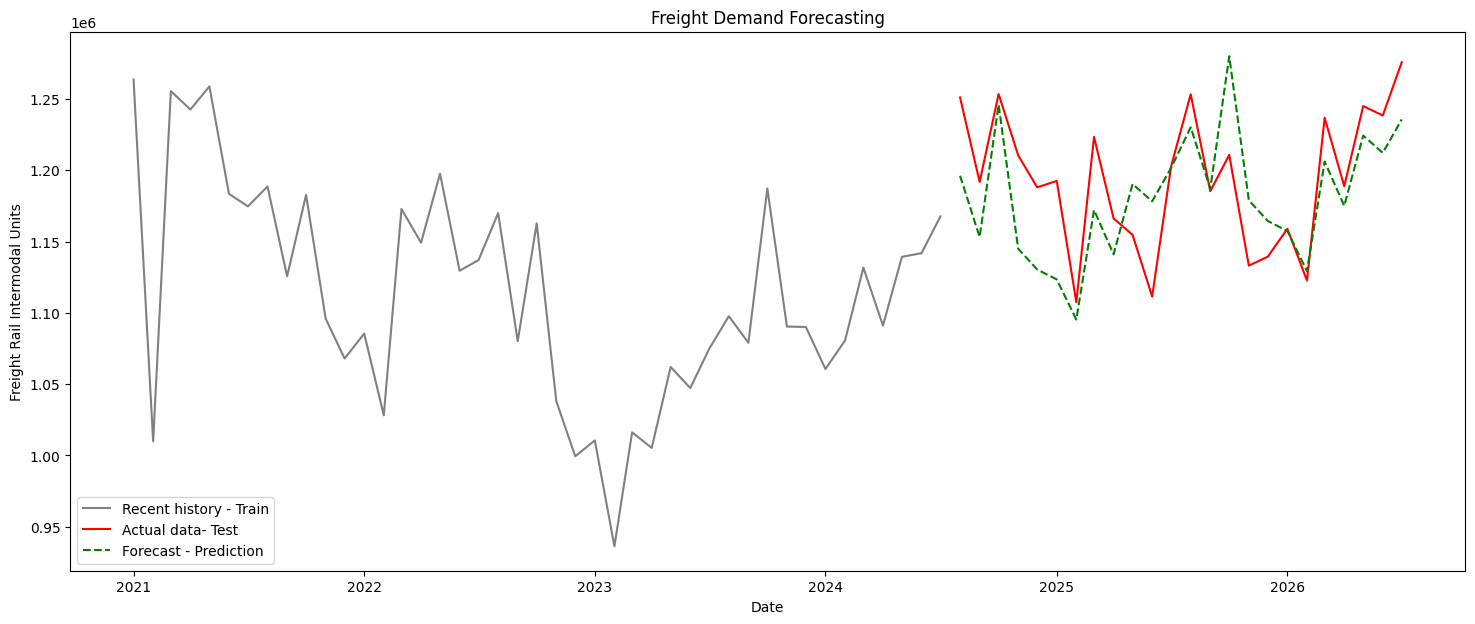

In [158]:
plt.figure(figsize=(18,7))
plt.plot(train_recent['2021':], label='Recent history - Train', color='grey')
plt.plot(test, label='Actual data- Test', color='red')
plt.plot(forecast, label='Forecast - Prediction', color='green', linestyle='--')
plt.xlabel('Date')
plt.ylabel('Freight Rail Intermodal Units')
plt.title('Freight Demand Forecasting')
plt.legend()
plt.show()



### Observations
1. The SARIMA model had a MAPE of 2.8% (MAE of about 32,900 units per month) over the 24 test months, compared with 3.8% for the naive baseline and 6.9% for the seasonal naive baseline.
2. The model performed better because it captured both the current level of demand and the yearly seasonal pattern, whereas each baseline captured only one of the two.
3. A lower error did not always mean a more useful forecast. The naive baseline had a lower error than the seasonal naive baseline, but being a flat line it could not show which months would be busy.
4. When several models fitted equally well, the simplest one was preferred.
5. The model was evaluated on a single 24-month test period with no major shock. A model of this type would not have predicted the 2008-09 dip or the drop in 2020, and forecasts further ahead are less certain.
6. Testing the model over several different periods and comparing it with other forecasting methods could be explored in future work.